# EfficientNetB0 para Cassava

**Asignatura:** Inteligencia Artificial
**Proyecto:** Clasificación de enfermedades foliares de yuca
**Grupo:** 1 · **Modelo asignado:** EfficientNetB0

## Objetivo
Entrenar EfficientNetB0 con la misma preparación de datos de `Preparacion_Cassava.ipynb`
(redimensionamiento a 224 × 224 con relleno, lotes de 32) y comparar tres corridas:

1. **Sin ponderación**: la base congelada, igual que la primera corrida de DenseNet121.
2. **Ponderación moderada**: pesos de clase acercados a 1, como en la tercera corrida de DenseNet121.
3. **Ajuste fino**: se parte de la mejor corrida congelada y se descongela el 30 % superior de la base.

Cada corrida guarda `historial.csv`, `mejor_modelo.keras`, las curvas y la matriz de confusión
en `cassava/resultados/efficientnetb0/`.

## Preparación de los datos
Se ejecutan los pasos de `Preparacion_Cassava.ipynb` sin cambios (se omiten solo las gráficas de exploración, que ya están en ese notebook).

In [1]:
# PASO 1: Importación y verificación de librerías
import tensorflow as tf
import tensorflow_datasets as tfds
import matplotlib.pyplot as plt
import numpy as np

# Mostrar versiones utilizadas
print("TensorFlow:", tf.__version__)
print("TensorFlow Datasets:", tfds.__version__)
# Comprobar si existe una GPU disponible
print("GPU disponible:", tf.config.list_physical_devices("GPU"))
print("\nLibrerías importadas correctamente.")

TensorFlow: 2.21.0
TensorFlow Datasets: 4.9.10


GPU disponible: []

Librerías importadas correctamente.


In [2]:
# PASO 2: Carga del dataset Cassava
# Descargar el dataset y cargar sus tres particiones originales
(ds_train, ds_val, ds_test), info = tfds.load(
    "cassava",
    split=["train", "validation", "test"],
    with_info=True,
    as_supervised=False,
    shuffle_files=False
)
# Confirmar que el dataset fue cargado correctamente
print("Cassava descargado y particiones cargadas correctamente.")

Cassava descargado y particiones cargadas correctamente.


In [3]:
# PASO 3: Análisis de metadatos del dataset Cassava
# Mostrar información general del dataset
print("Nombre del dataset:", info.name)
print("Versión:", info.version)

# Mostrar la cantidad de imágenes por conjunto
print("\n--- DISTRIBUCIÓN DE DATOS ---")
total = 0

for nombre, datos in info.splits.items():
    print(f"{nombre}: {datos.num_examples} imágenes")
    total += datos.num_examples

print("Total de imágenes:", total)

# Mostrar la cantidad de clases y sus etiquetas
print("\n--- CLASES Y ETIQUETAS ---")
clases = info.features["label"].names

print("Número de clases:", len(clases))

for codigo, nombre in enumerate(clases):
    print(f"Etiqueta {codigo}: {nombre}")

# Mostrar las características de las imágenes
print("\n--- CARACTERÍSTICAS DE LAS IMÁGENES ---")
print("Dimensiones:", info.features["image"].shape)
print("Tipo de dato:", info.features["image"].np_dtype)
print("Características disponibles:", list(info.features.keys()))

Nombre del dataset: cassava
Versión: 0.1.0

--- DISTRIBUCIÓN DE DATOS ---
train: 5656 imágenes
test: 1885 imágenes
validation: 1889 imágenes
Total de imágenes: 9430

--- CLASES Y ETIQUETAS ---
Número de clases: 5
Etiqueta 0: cbb
Etiqueta 1: cbsd
Etiqueta 2: cgm
Etiqueta 3: cmd
Etiqueta 4: healthy

--- CARACTERÍSTICAS DE LAS IMÁGENES ---
Dimensiones: (None, None, 3)
Tipo de dato: <class 'numpy.uint8'>
Características disponibles: ['image', 'image/filename', 'label']


In [4]:
# PASO 5: Preparación de datos para el entrenamiento
# Definir parámetros generales
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

# Función para redimensionar cada imagen y conservar su etiqueta
def preparar_imagen(registro):
    imagen = tf.image.resize_with_pad(
        registro["image"],
        IMG_SIZE[0],
        IMG_SIZE[1],
        antialias=True,)
    # Mantener los píxeles float32 en el rango común de 0 a 255.
    imagen = tf.clip_by_value(imagen, 0.0, 255.0)
    return imagen, registro["label"]
# Función para organizar los datos en lotes
def preparar_dataset(dataset, entrenamiento=False):

    # Mezclar únicamente las imágenes de entrenamiento
    if entrenamiento:
        dataset = dataset.shuffle(1000, seed=42)
    # Redimensionar las imágenes
    dataset = dataset.map(
        preparar_imagen, num_parallel_calls=AUTOTUNE
    )
    # Agrupar las imágenes y optimizar su lectura
    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(AUTOTUNE)
    return dataset
# Preparar Train, Validation y Test
train_preparado = preparar_dataset(ds_train, entrenamiento=True)
val_preparado = preparar_dataset(ds_val)
test_preparado = preparar_dataset(ds_test)

print("Datos preparados correctamente.")

# Comprobar las dimensiones de un lote
for imagenes, etiquetas in train_preparado.take(1):
    print("Dimensiones del lote:", imagenes.shape)
    print("Dimensiones de etiquetas:", etiquetas.shape)
    print("Tipo de dato:", imagenes.dtype)

Datos preparados correctamente.

Dimensiones del lote: (32, 224, 224, 3)
Dimensiones de etiquetas: (32,)
Tipo de dato: <dtype: 'float32'>


In [5]:
# PASO 8: Verificar las entradas antes de entrenar la CNN propia
for nombre, dataset in [
    ("Train", train_preparado),
    ("Validation", val_preparado),
]:
    imagenes, etiquetas = next(iter(dataset))

    tf.debugging.assert_shapes([
        (imagenes, ("lote", 224, 224, 3)),
        (etiquetas, ("lote",)),
    ])
    tf.debugging.assert_all_finite(imagenes, f"{nombre}: píxeles no finitos")
    tf.debugging.assert_greater_equal(imagenes, 0.0)
    tf.debugging.assert_less_equal(imagenes, 255.0)
    tf.debugging.assert_greater_equal(etiquetas, tf.cast(0, etiquetas.dtype))
    tf.debugging.assert_less(
        etiquetas, tf.cast(len(clases), etiquetas.dtype)
    )

    print(
        f"{nombre} | imágenes: {imagenes.shape} | "
        f"etiquetas: {etiquetas.shape} | "
        f"píxeles: {float(tf.reduce_min(imagenes)):.1f} a "
        f"{float(tf.reduce_max(imagenes)):.1f}"
    )
print("Los lotes de Train y Validation pasaron la verificación.")

Train | imágenes: (32, 224, 224, 3) | etiquetas: (32,) | píxeles: 0.0 a 255.0
Validation | imágenes: (32, 224, 224, 3) | etiquetas: (32,) | píxeles: 0.0 a 255.0
Los lotes de Train y Validation pasaron la verificación.


## Funciones de entrenamiento y evaluación

EfficientNetB0 recibe imágenes RGB de 224 × 224 con valores de 0 a 255. A diferencia de DenseNet121,
**no necesita** `Rescaling` ni `Normalization`, porque su normalización viene dentro del modelo.
Se agrega un `Dropout` de 0,2 antes de la capa de salida para reducir el sobreajuste.
Cada corrida construye un modelo nuevo para que los resultados no se mezclen.

In [6]:
# PASO 9: Funciones comunes para entrenar, guardar y evaluar EfficientNetB0
import csv
import json
from datetime import datetime
from pathlib import Path
from tensorflow import keras
from tensorflow.keras import layers

PRUEBA_RAPIDA = False  # True solo para comprobar el código con pocos lotes

carpeta_actual = Path.cwd()
carpeta_dataset = (
    carpeta_actual if carpeta_actual.name == "cassava"
    else carpeta_actual / "cassava"
)
if not (carpeta_dataset / "EfficientNetB0.ipynb").is_file():
    raise FileNotFoundError("Abre la carpeta BeanCass AI en VS Code y ejecuta desde allí.")

carpeta_resultados = carpeta_dataset / "resultados" / "efficientnetb0"


def construir_efficientnet(n_clases, nombre):
    """EfficientNetB0 preentrenado en ImageNet con una capa de salida nueva."""
    keras.utils.set_random_seed(42)
    base = keras.applications.EfficientNetB0(
        include_top=False,
        weights="imagenet",
        input_shape=(*IMG_SIZE, 3),
        pooling="avg",
    )
    # Fase inicial: la base queda congelada y solo aprende la capa nueva.
    base.trainable = False

    # EfficientNetB0 ya trae su propia normalización interna y espera
    # píxeles de 0 a 255, así que NO se agrega Rescaling ni Normalization.
    entrada = keras.Input(shape=(*IMG_SIZE, 3), name="imagen")
    caracteristicas = base(entrada, training=False)
    x = layers.Dropout(0.2, name="dropout")(caracteristicas)
    salida = layers.Dense(n_clases, activation="softmax", name=f"clasificacion_{nombre}")(x)
    modelo = keras.Model(entrada, salida, name=f"efficientnetb0_{nombre}")
    return modelo, base


def compilar(modelo, lr):
    modelo.compile(
        optimizer=keras.optimizers.Adam(learning_rate=lr),
        loss=keras.losses.SparseCategoricalCrossentropy(),
        metrics=["accuracy"],
    )


def entrenar(modelo, prefijo, epocas, pesos_clase=None, datos_train=None):
    """Entrena y guarda historial.csv y mejor_modelo.keras en su propia carpeta."""
    datos_train = train_preparado if datos_train is None else datos_train
    datos_val = val_preparado
    if PRUEBA_RAPIDA:
        datos_train, datos_val, epocas = datos_train.take(2), datos_val.take(1), 1

    nombre_corrida = datetime.now().strftime(f"{prefijo}_%Y%m%d_%H%M%S")
    carpeta = carpeta_resultados / nombre_corrida
    carpeta.mkdir(parents=True, exist_ok=False)
    ruta_modelo = carpeta / "mejor_modelo.keras"
    print("Los resultados se guardarán en", carpeta.resolve())

    modelo.fit(
        datos_train,
        validation_data=datos_val,
        epochs=epocas,
        class_weight=pesos_clase,
        callbacks=[
            # Anotar las métricas de cada época.
            keras.callbacks.CSVLogger(str(carpeta / "historial.csv")),
            # Guardar el modelo de la época con menor pérdida en Validation.
            keras.callbacks.ModelCheckpoint(
                filepath=str(ruta_modelo), monitor="val_loss",
                mode="min", save_best_only=True,
            ),
            # Detener si Validation no mejora durante dos épocas seguidas.
            keras.callbacks.EarlyStopping(
                monitor="val_loss", mode="min", patience=2,
                restore_best_weights=True,
            ),
        ],
        verbose=2,
    )
    return carpeta


def evaluar(carpeta, titulo):
    """Matriz de confusión, métricas por clase y figuras de la corrida."""
    modelo = keras.models.load_model(str(carpeta / "mejor_modelo.keras"), compile=False)
    nombres = list(clases)
    matriz = np.zeros((len(nombres), len(nombres)), dtype=int)
    datos_val = val_preparado.take(1) if PRUEBA_RAPIDA else val_preparado
    for imagenes, etiquetas in datos_val:
        predicciones = np.argmax(modelo(imagenes, training=False).numpy(), axis=1)
        np.add.at(matriz, (etiquetas.numpy(), predicciones), 1)

    aciertos = matriz.diagonal()
    reales = matriz.sum(axis=1)
    predichas = matriz.sum(axis=0)
    precision = aciertos / np.maximum(predichas, 1)
    recall = aciertos / np.maximum(reales, 1)
    f1 = 2 * aciertos / np.maximum(reales + predichas, 1)
    exactitud = aciertos.sum() / max(reales.sum(), 1)

    print("Orden de clases:", nombres)
    print("Matriz de confusión (filas reales, columnas predichas):")
    print(matriz)
    print("\nClase              Aciertos   Precisión   Recall      F1")
    for i, clase in enumerate(nombres):
        print(f"{clase:<18} {aciertos[i]:>4}/{reales[i]:<5}"
              f" {precision[i]:>9.2%} {recall[i]:>9.2%} {f1[i]:>8.4f}")
    print(f"\nExactitud en Validation: {exactitud:.2%}")
    print(f"F1 macro: {f1.mean():.4f}")

    # Guardar las métricas en un archivo para comparar corridas.
    resumen = {
        "corrida": carpeta.name,
        "exactitud_validation": round(float(exactitud), 4),
        "f1_macro_validation": round(float(f1.mean()), 4),
        "f1_por_clase": {c: round(float(v), 4) for c, v in zip(nombres, f1)},
        "recall_por_clase": {c: round(float(v), 4) for c, v in zip(nombres, recall)},
        "matriz_confusion": matriz.tolist(),
    }
    (carpeta / "metricas_validation.json").write_text(
        json.dumps(resumen, indent=2, ensure_ascii=False), encoding="utf-8")

    # Figura 1: matriz de confusión en porcentaje de cada clase real.
    porcentajes = 100 * matriz / np.maximum(matriz.sum(axis=1, keepdims=True), 1)
    fig, ax = plt.subplots(figsize=(7.5, 5.5), layout="constrained")
    imagen = ax.imshow(porcentajes, cmap="Blues", vmin=0, vmax=100)
    fig.colorbar(imagen, ax=ax, label="Porcentaje de la clase real")
    ax.set_xticks(range(len(nombres)), labels=nombres, rotation=20)
    ax.set_yticks(range(len(nombres)), labels=nombres)
    ax.set_xlabel("Clase predicha")
    ax.set_ylabel("Clase real")
    ax.set_title(f"{titulo}\nValidación · F1 macro {f1.mean():.4f}")
    for fila, columna in np.ndindex(matriz.shape):
        color = "white" if porcentajes[fila, columna] > 55 else "black"
        ax.text(columna, fila, f"{matriz[fila, columna]}\n{porcentajes[fila, columna]:.0f}%",
                ha="center", va="center", color=color, fontsize=9)
    fig.savefig(carpeta / "matriz_confusion_validation.png", dpi=150)
    plt.show()

    # Figura 2: curvas de exactitud y pérdida a partir de historial.csv.
    with (carpeta / "historial.csv").open(encoding="utf-8", newline="") as archivo:
        registros = list(csv.DictReader(archivo))
    epocas = [int(fila["epoch"]) + 1 for fila in registros]
    mejor = min(registros, key=lambda fila: float(fila["val_loss"]))
    fig, ejes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
    fig.suptitle(titulo)
    for eje, metrica, nombre_metrica in [
        (ejes[0], "accuracy", "Exactitud"), (ejes[1], "loss", "Pérdida")
    ]:
        eje.plot(epocas, [float(f[metrica]) for f in registros], marker="o", label="Train")
        eje.plot(epocas, [float(f[f"val_{metrica}"]) for f in registros], marker="o", label="Validation")
        eje.axvline(int(mejor["epoch"]) + 1, color="gray", linestyle="--", label="Mejor época")
        eje.set_title(nombre_metrica)
        eje.set_xlabel("Época")
        eje.set_xticks(epocas)
        eje.grid(alpha=0.3)
        eje.legend()
    ejes[0].set_ylim(0, 1)
    fig.savefig(carpeta / "curvas_entrenamiento.png", dpi=150)
    plt.show()
    return resumen


def ajuste_fino(carpeta_origen, prefijo, epocas, pesos_clase=None, fraccion=0.30, datos_train=None):
    """Parte del mejor modelo congelado y descongela la parte alta de la base."""
    modelo = keras.models.load_model(str(carpeta_origen / "mejor_modelo.keras"), compile=False)
    base = next(capa for capa in modelo.layers if isinstance(capa, keras.Model))
    base.trainable = True
    corte = int(len(base.layers) * (1 - fraccion))
    for i, capa in enumerate(base.layers):
        # Las capas bajas siguen congeladas y las BatchNormalization también,
        # para no desordenar las estadísticas aprendidas en ImageNet.
        capa.trainable = i >= corte and not isinstance(capa, layers.BatchNormalization)
    entrenables = sum(capa.trainable for capa in base.layers)
    print(f"Capas de la base descongeladas: {entrenables} de {len(base.layers)}")
    # Tasa de aprendizaje 10 veces menor para ajustar sin romper lo aprendido.
    compilar(modelo, 1e-4)
    return entrenar(modelo, prefijo, epocas, pesos_clase, datos_train)

print("Funciones listas. Resultados en:", carpeta_resultados.resolve())

Funciones listas. Resultados en: C:\Users\USER\Downloads\Entrenamiento\2_LO_QUE_USE\BeanCass-AI\cassava\resultados\efficientnetb0


## Corrida 1 · EfficientNetB0 sin ponderación

In [7]:
# Corrida 1: base congelada, sin ponderación, 5 épocas y Adam con lr = 0,001
modelo, base = construir_efficientnet(len(clases), "cassava")
compilar(modelo, 1e-3)
print(f"Parámetros totales: {modelo.count_params():,} · entrenables: "
      f"{sum(int(np.prod(p.shape)) for p in modelo.trainable_weights):,}")
carpeta_sin_ponderacion = entrenar(modelo, "corrida", epocas=5)

Parámetros totales: 4,055,976 · entrenables: 6,405
Los resultados se guardarán en C:\Users\USER\Downloads\Entrenamiento\2_LO_QUE_USE\BeanCass-AI\cassava\resultados\efficientnetb0\corrida_20261116_201557
Epoch 1/5


C:\Users\USER\Downloads\Entrenamiento\2_LO_QUE_USE\BeanCass-AI\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


177/177 - 118s - 668ms/step - accuracy: 0.6370 - loss: 0.9682 - val_accuracy: 0.7279 - val_loss: 0.7662


Epoch 2/5


177/177 - 110s - 624ms/step - accuracy: 0.7247 - loss: 0.7713 - val_accuracy: 0.7501 - val_loss: 0.7085


Epoch 3/5


177/177 - 110s - 620ms/step - accuracy: 0.7392 - loss: 0.7173 - val_accuracy: 0.7650 - val_loss: 0.6730


Epoch 4/5


177/177 - 109s - 614ms/step - accuracy: 0.7583 - loss: 0.6823 - val_accuracy: 0.7787 - val_loss: 0.6492


Epoch 5/5


177/177 - 111s - 624ms/step - accuracy: 0.7661 - loss: 0.6606 - val_accuracy: 0.7724 - val_loss: 0.6460


Orden de clases: ['cbb', 'cbsd', 'cgm', 'cmd', 'healthy']
Matriz de confusión (filas reales, columnas predichas):
[[ 61  64   9  17   5]
 [ 18 390   9  59   6]
 [  3  26 132  90   7]
 [  2  50  15 817   3]
 [  2  31   1  13  59]]

Clase              Aciertos   Precisión   Recall      F1
cbb                  61/156      70.93%    39.10%   0.5041
cbsd                390/482      69.52%    80.91%   0.7478
cgm                 132/258      79.52%    51.16%   0.6226
cmd                 817/887      82.03%    92.11%   0.8678
healthy              59/106      73.75%    55.66%   0.6344

Exactitud en Validation: 77.24%
F1 macro: 0.6754


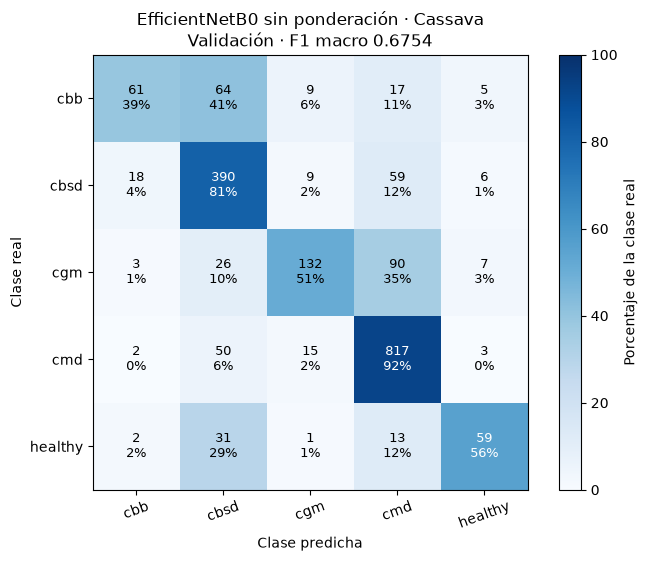

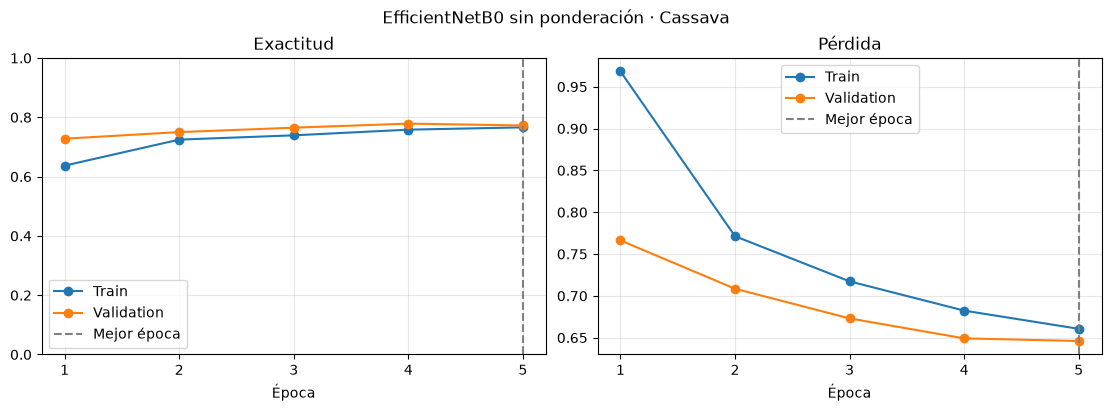

In [8]:
resumen_1 = evaluar(carpeta_sin_ponderacion, "EfficientNetB0 sin ponderación · Cassava")

## Corrida 2 · Ponderación moderada de clases

Cassava está desbalanceado: cmd tiene 2658 fotos de Train y healthy solo 316.
Los pesos "balanceados" (total / (clases × fotos de la clase)) castigan demasiado y en DenseNet121
bajaron la exactitud, así que se usa la versión moderada: `(1 + peso) / 2`.

In [9]:
# Corrida 2: base congelada con pesos de clase moderados
conteos_train = {"cbb": 466, "cbsd": 1443, "cgm": 773, "cmd": 2658, "healthy": 316}
total_train = sum(conteos_train.values())
pesos_originales = {
    indice: total_train / (len(clases) * conteos_train[nombre])
    for indice, nombre in enumerate(clases)
}
pesos_moderados = {indice: (1.0 + peso) / 2.0 for indice, peso in pesos_originales.items()}
for indice, nombre in enumerate(clases):
    print(f"{nombre}: {conteos_train[nombre]} fotos, peso {pesos_moderados[indice]:.2f}")

modelo, base = construir_efficientnet(len(clases), "cassava")
compilar(modelo, 1e-3)
carpeta_moderada = entrenar(modelo, "ponderada_moderada", epocas=5, pesos_clase=pesos_moderados)

cbb: 466 fotos, peso 1.71
cbsd: 1443 fotos, peso 0.89
cgm: 773 fotos, peso 1.23
cmd: 2658 fotos, peso 0.71
healthy: 316 fotos, peso 2.29


Los resultados se guardarán en C:\Users\USER\Downloads\Entrenamiento\2_LO_QUE_USE\BeanCass-AI\cassava\resultados\efficientnetb0\ponderada_moderada_20261116_202619
Epoch 1/5


C:\Users\USER\Downloads\Entrenamiento\2_LO_QUE_USE\BeanCass-AI\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


177/177 - 118s - 669ms/step - accuracy: 0.6351 - loss: 1.1107 - val_accuracy: 0.7417 - val_loss: 0.7761


Epoch 2/5


177/177 - 110s - 620ms/step - accuracy: 0.7184 - loss: 0.8797 - val_accuracy: 0.7517 - val_loss: 0.7304


... (2 outputs left out)

Epoch 4/5


177/177 - 108s - 613ms/step - accuracy: 0.7481 - loss: 0.7865 - val_accuracy: 0.7792 - val_loss: 0.6621


Epoch 5/5


177/177 - 109s - 616ms/step - accuracy: 0.7624 - loss: 0.7534 - val_accuracy: 0.7787 - val_loss: 0.6768


Orden de clases: ['cbb', 'cbsd', 'cgm', 'cmd', 'healthy']
Matriz de confusión (filas reales, columnas predichas):
[[ 85  38  10  17   6]
 [ 40 350  16  62  14]
 [  4  13 176  57   8]
 [  3  41  42 797   4]
 [  5  18   5  14  64]]

Clase              Aciertos   Precisión   Recall      F1
cbb                  85/156      62.04%    54.49%   0.5802
cbsd                350/482      76.09%    72.61%   0.7431
cgm                 176/258      70.68%    68.22%   0.6943
cmd                 797/887      84.16%    89.85%   0.8691
healthy              64/106      66.67%    60.38%   0.6337

Exactitud en Validation: 77.92%
F1 macro: 0.7041


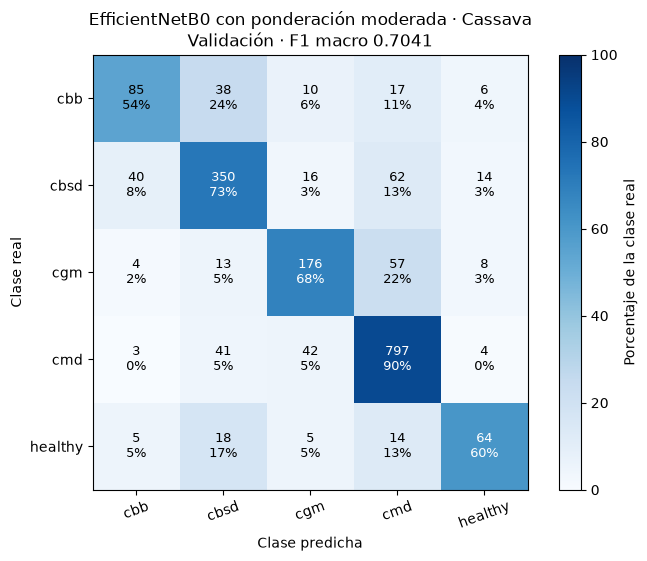

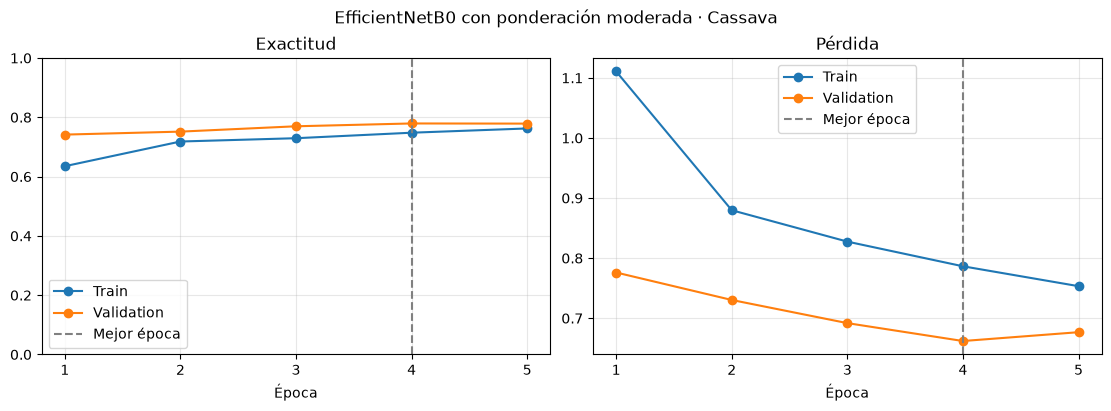

In [10]:
resumen_2 = evaluar(carpeta_moderada, "EfficientNetB0 con ponderación moderada · Cassava")

## Corrida 3 · Ajuste fino (fine-tuning)

Con la base congelada, EfficientNetB0 solo puede usar lo que aprendió con ImageNet.
En el ajuste fino se descongela el 30 % superior de la base (menos las BatchNormalization)
y se entrena con una tasa de aprendizaje 10 veces menor (0,0001), partiendo de la mejor corrida congelada.
Así la red adapta sus filtros a los detalles de las hojas de yuca, que es donde se confunden cgm, healthy y cmd.

In [11]:
# Corrida 3: ajuste fino desde la mejor de las dos corridas congeladas
mejor_congelada = max([(resumen_1, carpeta_sin_ponderacion), (resumen_2, carpeta_moderada)],
                      key=lambda par: par[0]["f1_macro_validation"])
print("Se parte de:", mejor_congelada[1].name)
usar_pesos = pesos_moderados if mejor_congelada[1] == carpeta_moderada else None
carpeta_ajuste = ajuste_fino(mejor_congelada[1], "ajuste_fino", epocas=8, pesos_clase=usar_pesos)

Se parte de: ponderada_moderada_20261116_202619


Capas de la base descongeladas: 57 de 239
Los resultados se guardarán en C:\Users\USER\Downloads\Entrenamiento\2_LO_QUE_USE\BeanCass-AI\cassava\resultados\efficientnetb0\ajuste_fino_20261116_203639
Epoch 1/8


C:\Users\USER\Downloads\Entrenamiento\2_LO_QUE_USE\BeanCass-AI\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


177/177 - 147s - 832ms/step - accuracy: 0.7597 - loss: 0.7334 - val_accuracy: 0.7814 - val_loss: 0.6405


Epoch 2/8


177/177 - 137s - 776ms/step - accuracy: 0.8179 - loss: 0.5675 - val_accuracy: 0.7898 - val_loss: 0.6182


... (2 outputs left out)

Epoch 4/8


177/177 - 134s - 755ms/step - accuracy: 0.8856 - loss: 0.3571 - val_accuracy: 0.8121 - val_loss: 0.5506


Epoch 5/8


177/177 - 138s - 778ms/step - accuracy: 0.9146 - loss: 0.2721 - val_accuracy: 0.8264 - val_loss: 0.5559


Orden de clases: ['cbb', 'cbsd', 'cgm', 'cmd', 'healthy']
Matriz de confusión (filas reales, columnas predichas):
[[ 97  31   9  12   7]
 [ 31 372  16  51  12]
 [  4  15 195  37   7]
 [  3  26  42 810   6]
 [  1  12   7   7  79]]

Clase              Aciertos   Precisión   Recall      F1
cbb                  97/156      71.32%    62.18%   0.6644
cbsd                372/482      81.58%    77.18%   0.7932
cgm                 195/258      72.49%    75.58%   0.7400
cmd                 810/887      88.33%    91.32%   0.8980
healthy              79/106      71.17%    74.53%   0.7281

Exactitud en Validation: 82.21%
F1 macro: 0.7647


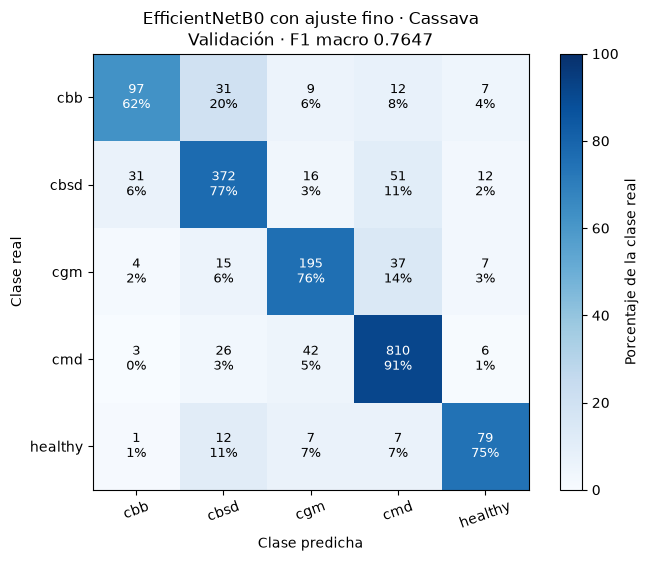

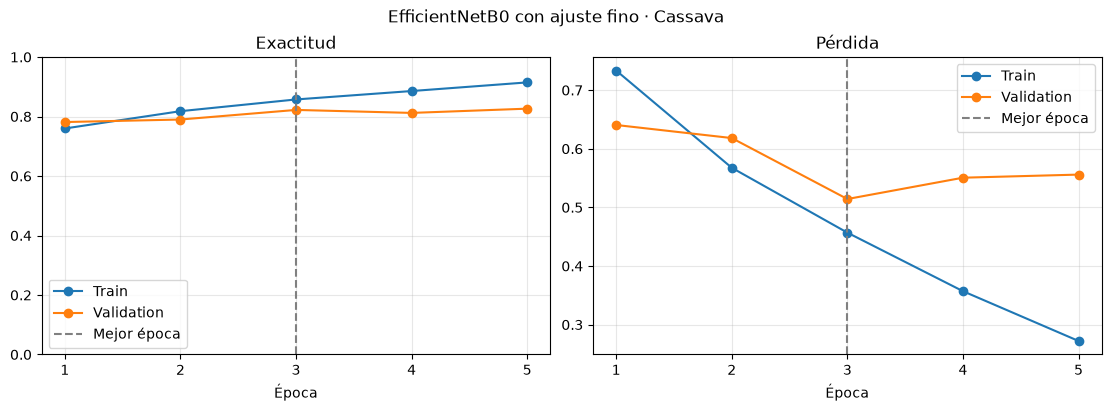

In [12]:
resumen_3 = evaluar(carpeta_ajuste, "EfficientNetB0 con ajuste fino · Cassava")

## Comparación de las corridas en Validation

In [13]:
# Tabla comparativa: la mejor corrida es la de mayor F1 macro en Validation
resumenes = [resumen_1, resumen_2, resumen_3]
print(f"{'Corrida':<38} {'Exactitud':>10} {'F1 macro':>9}  " + "  ".join(f"{c:>8}" for c in clases))
for r in resumenes:
    print(f"{r['corrida']:<38} {r['exactitud_validation']:>10.2%} {r['f1_macro_validation']:>9.4f}  "
          + "  ".join(f"{r['f1_por_clase'][c]:>8.4f}" for c in clases))
mejor = max(resumenes, key=lambda r: r["f1_macro_validation"])
print("\nMejor corrida de EfficientNetB0 en Cassava:", mejor["corrida"])
(carpeta_resultados / "comparacion_corridas.json").write_text(
    json.dumps({"mejor": mejor["corrida"], "corridas": resumenes}, indent=2, ensure_ascii=False),
    encoding="utf-8")

Corrida                                 Exactitud  F1 macro       cbb      cbsd       cgm       cmd   healthy
corrida_20261116_201557                    77.24%    0.6754    0.5041    0.7478    0.6226    0.8678    0.6344
ponderada_moderada_20261116_202619         77.92%    0.7041    0.5802    0.7431    0.6943    0.8691    0.6337
ajuste_fino_20261116_203639                82.21%    0.7647    0.6644    0.7932    0.7400    0.8980    0.7281

Mejor corrida de EfficientNetB0 en Cassava: ajuste_fino_20261116_203639


2833